# 01 · Data sources, the unified dataset and EDA

**Question:** after an information shock (an earnings release, or a ≥10% crash), does a US
stock keep moving the same way (**drift** — HW1 idea: momentum + PEAD) or snap back
(**reversal** — HW5 Q3: panic vs permanent damage)? Target: `growth_future_10d ≥ 1.02`
(enter at the next open, exit at the close 10 sessions later, ≥ +2% ≈ costs + profit).


In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})
from driftrev import config, store, artifacts, dataset, features, models, simulate, analysis, pipeline
print("data dir:", config.DATA_DIR)

data dir: /Users/mac/Documents/New project/stock-data-analysis/project/data


In [2]:
events = store.read_table("events")
with store.connect() as con:
    sizes = {t: con.execute(f"select count(*) from {t}").fetchone()[0]
             for t in ["prices", "market", "macro", "filings", "eps_facts", "pageviews", "daily_panel", "events"]}
print({k: f"{v:,}" for k, v in sizes.items()}); print("total records:", f"{sum(sizes.values()):,}")

{'prices': '4,426,339', 'market': '50,226', 'macro': '18,348', 'filings': '1,896,174', 'eps_facts': '334,462', 'pageviews': '4,522,878', 'daily_panel': '4,425,338', 'events': '176,802'}
total records: 15,850,567


### Events per family and year

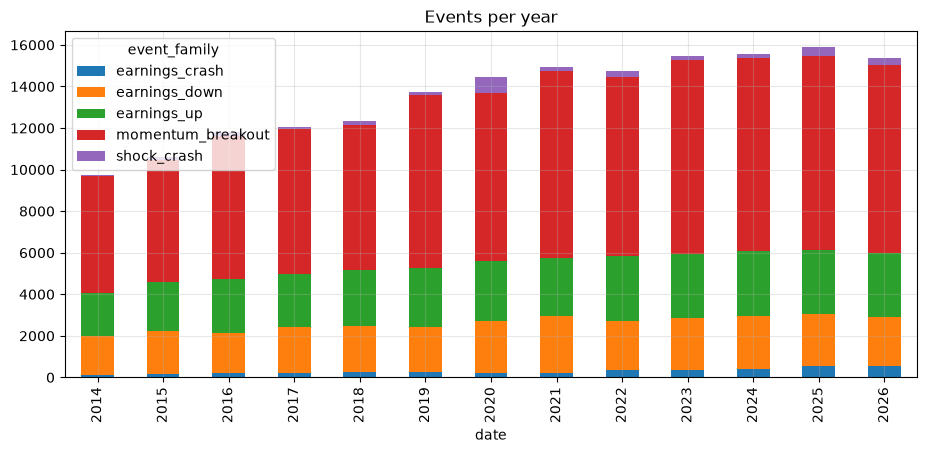

event_family,earnings_crash,earnings_down,earnings_up,momentum_breakout,shock_crash
date,,,,,
2014,108,1878,2082,5601,81
2015,179,2059,2366,5860,158
2016,222,1937,2579,6856,219
2017,191,2239,2554,6981,107
2018,263,2208,2714,6974,180
2019,266,2161,2859,8304,158
2020,195,2508,2907,8094,769
2021,209,2744,2800,8982,183
2022,355,2380,3119,8587,314


In [3]:
tab = events.pivot_table(index=events.date.dt.year, columns="event_family", values="ticker", aggfunc="size", fill_value=0)
tab.plot(kind="bar", stacked=True, title="Events per year"); plt.show(); tab

### Target: distribution of the 10-day forward return by family

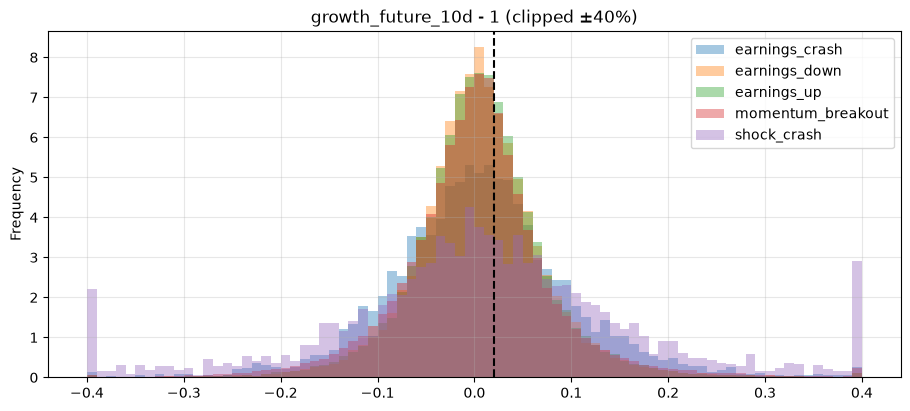

,n,base_rate,mean_10d,median_10d,mean_10d_vs_spy
event_family,,,,,
earnings_crash,3771,0.4187,0.0070,0.0046,0.0014
earnings_down,29862,0.3782,0.0057,0.0040,-0.0004
earnings_up,36015,0.3848,0.0058,0.0046,-0.0003
momentum_breakout,102818,0.3676,0.0026,0.0024,-0.0007
shock_crash,3256,0.4622,0.0168,0.0091,0.0141


In [4]:
ml, feats = dataset.prepare(events)
known = ml[ml[dataset.TARGET].notna()]
fig, ax = plt.subplots()
for fam, g in known.groupby("event_family"):
    (g.growth_future_10d - 1).clip(-0.4, 0.4).plot(kind="hist", bins=80, alpha=0.4, density=True, ax=ax, label=fam)
ax.axvline(0.02, color="k", ls="--"); ax.legend(); ax.set_title("growth_future_10d - 1 (clipped ±40%)"); plt.show()
known.groupby("event_family").agg(n=("ticker", "size"), base_rate=(dataset.TARGET, "mean"),
    mean_10d=("growth_future_10d", lambda s: s.mean() - 1), median_10d=("growth_future_10d", lambda s: s.median() - 1),
    mean_10d_vs_spy=("growth_future_10d_vs_spy", lambda s: s.mean() - 1)).round(4)

### Event study: drift or reversal? (mean forward return vs SPY at 5/10/20 days)

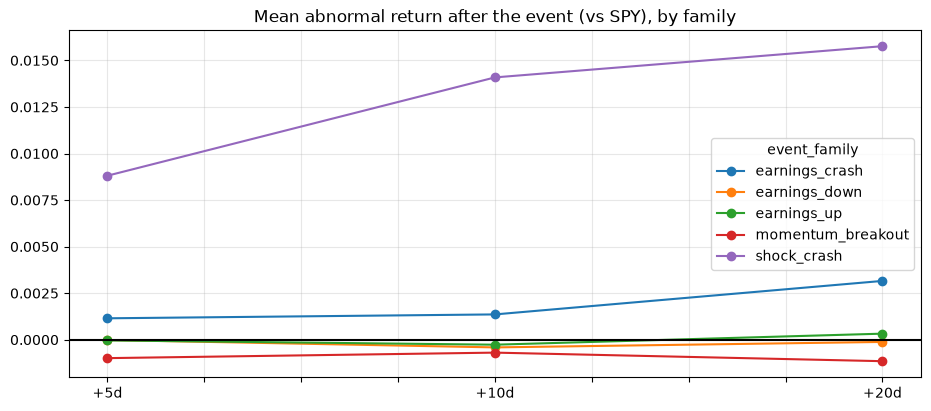

,+5d,+10d,+20d
event_family,,,
earnings_crash,0.0011,0.0014,0.0032
earnings_down,-0.0000,-0.0004,-0.0001
earnings_up,-0.0000,-0.0003,0.0003
momentum_breakout,-0.0010,-0.0007,-0.0012
shock_crash,0.0088,0.0141,0.0158


In [5]:
es = known.groupby("event_family")[["growth_future_5d_vs_spy", "growth_future_10d_vs_spy", "growth_future_20d_vs_spy"]].mean() - 1
es.columns = ["+5d", "+10d", "+20d"]
es.T.plot(marker="o", title="Mean abnormal return after the event (vs SPY), by family"); plt.axhline(0, color="k"); plt.show()
es.round(4)

### EDGAR taxonomy test (HW5 Q3, stage 1): do crash causes have different base rates?

In [6]:
crash = known[known.event_family.isin(["shock_crash", "earnings_crash"])]
crash.groupby("edgar_category").agg(n=("ticker", "size"), bounce_rate=(dataset.TARGET, "mean"),
    mean_10d=("growth_future_10d", lambda s: s.mean() - 1), mean_mae=("mae_10d", "mean")).sort_values("n", ascending=False).round(3)

,n,bounce_rate,mean_10d,mean_mae
edgar_category,,,,
earnings,3924,0.418,0.007,-0.069
none,2273,0.474,0.016,-0.140
regfd_other_8k,371,0.437,0.030,-0.113
offering,224,0.424,-0.010,-0.109
mgmt_change,111,0.477,0.030,-0.086
deal,83,0.422,0.010,-0.096
restatement_auditor,24,0.583,0.054,-0.095
bankruptcy_delisting,10,0.400,0.068,-0.198
impairment_restructuring,7,0.286,-0.031,-0.098


### PEAD (HW1): post-earnings drift by surprise (SUE) and by blended momentum

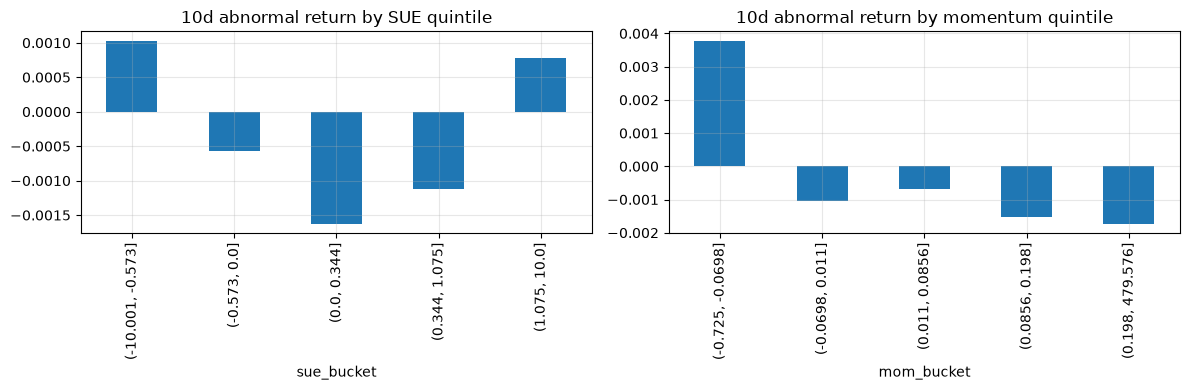

In [7]:
earn = known[known.event_family.str.startswith("earnings")].copy()
earn["sue_bucket"] = pd.qcut(earn["sue"], 5, duplicates="drop")
earn["mom_bucket"] = pd.qcut(earn["momentum_blend"], 5, duplicates="drop")
a = earn.groupby("sue_bucket", observed=True)["growth_future_10d_vs_spy"].mean() - 1
b = earn.groupby("mom_bucket", observed=True)["growth_future_10d_vs_spy"].mean() - 1
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
a.plot(kind="bar", ax=ax[0], title="10d abnormal return by SUE quintile")
b.plot(kind="bar", ax=ax[1], title="10d abnormal return by momentum quintile"); plt.tight_layout(); plt.show()

### Attention (Wikipedia pageviews) and market regime

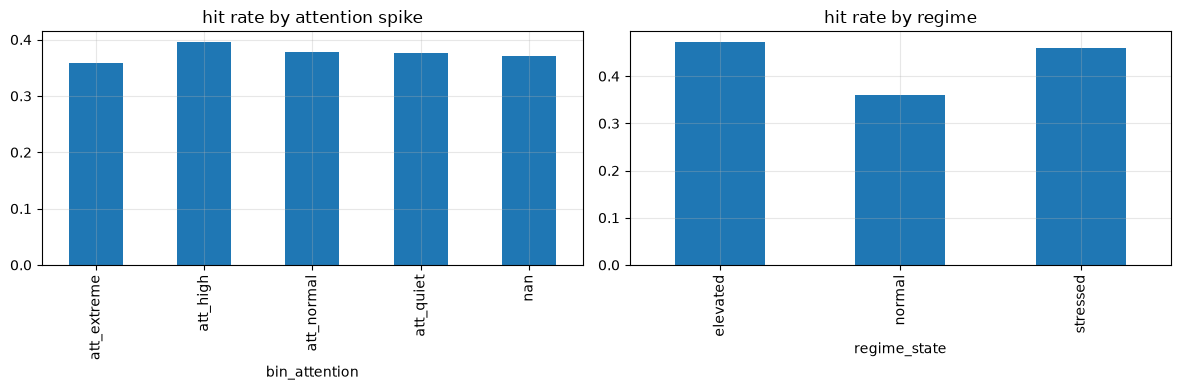

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
eda = dataset.add_engineered(events); eda = eda[eda[dataset.TARGET].notna()]   # bins before one-hot encoding
eda.groupby("bin_attention")[dataset.TARGET].mean().plot(kind="bar", ax=ax[0], title="hit rate by attention spike")
eda.groupby("regime_state")[dataset.TARGET].mean().plot(kind="bar", ax=ax[1], title="hit rate by regime"); plt.tight_layout(); plt.show()

### Correlation of features with the target

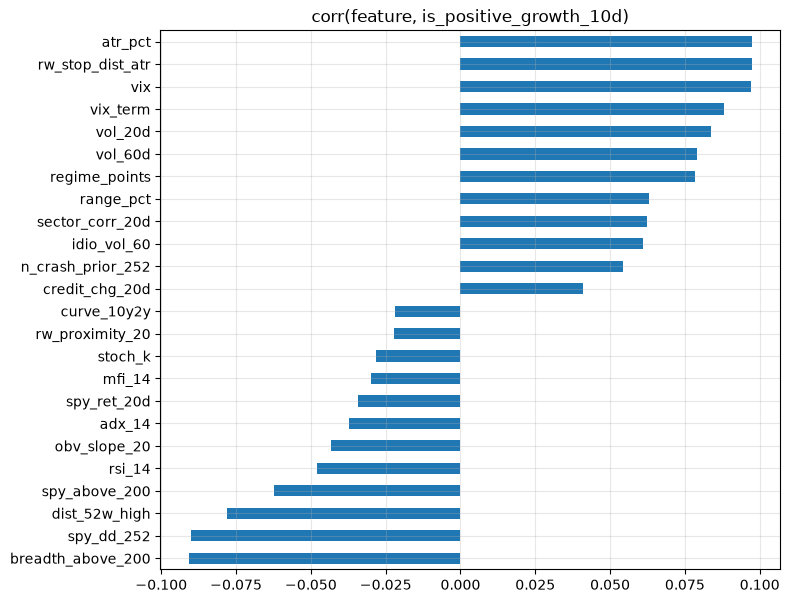

,corr_target,corr_growth
atr_pct,0.0975,0.0884
rw_stop_dist_atr,0.0975,0.0884
vix,0.0971,0.0662
breadth_above_200,-0.0908,-0.0520
spy_dd_252,-0.0901,-0.0585
vix_term,0.0881,0.0369
vol_20d,0.0837,0.0623
vol_60d,0.0790,0.0543
regime_points,0.0785,0.0419
dist_52w_high,-0.0779,-0.0503


In [9]:
num = [c for c in dataset.numeric_features() if c in known]
corr = known[num].corrwith(known[dataset.TARGET]).dropna().sort_values()
corr_g = known[num].corrwith(known.growth_future_10d).dropna()
top = pd.concat([corr.head(12), corr.tail(12)])
top.plot(kind="barh", figsize=(8, 7), title="corr(feature, is_positive_growth_10d)"); plt.show()
pd.DataFrame({"corr_target": corr, "corr_growth": corr_g}).sort_values("corr_target", key=abs, ascending=False).head(20).round(4)

### Dummy correlations (one-hot sets)

In [10]:
dums = [c for c in feats if c not in num]
dc = known[dums].corrwith(known[dataset.TARGET]).dropna().sort_values(key=abs, ascending=False)
dc.head(20).round(4)

regime_state_normal        -0.0788
regime_state_elevated       0.0723
bin_vix_vix_lt15           -0.0707
bin_vix_vix_20_30           0.0692
month_October               0.0554
bin_52w_near_high          -0.0551
bin_reaction_flat          -0.0507
bin_momentum_mom_down       0.0501
bin_vix_vix_gt30            0.0467
bin_52w_dd_gt50             0.0440
bin_rsi_rsi_gt70           -0.0420
bin_52w_dd_30_50            0.0382
month_November              0.0340
bin_reaction_up_3_10        0.0328
bin_momentum_mom_up        -0.0314
month_September            -0.0309
sector_Utilities           -0.0300
bin_52w_dd_15_30            0.0283
regime_state_stressed       0.0274
event_family_shock_crash    0.0245
dtype: float64